# Random Forests
### A walkthrough of `RandomForest.py` and `DecisionTreeRandomForest.py`

A **random forest** is a committee of decision trees. Each tree is grown on a different *bootstrap resample* of the training data, and at every node it may only consider a random subset of the features. The forest classifies a point by **majority vote** of its trees. Individually the trees are noisy, high-variance classifiers; averaging their votes cancels much of that noise while keeping their flexibility.

This notebook derives why that works and runs the implementation in this folder at every step. By the end you should be able to:

1. explain the variance problem of single deep trees and why **bagging** (bootstrap aggregating) addresses it;
2. derive the bootstrap's $1 - 1/e \approx 63.2\%$ coverage and the variance of an average of **correlated** trees, $\rho\sigma^2 + \frac{1-\rho}{T}\sigma^2$, and see why random feature subsets help by lowering $\rho$;
3. explain how `RandomForestClassifier` and its modified `DecisionTreeClassifier` sample, grow, vote and score feature importance, line by line;
4. follow a 3-tree forest through a 10-sample example;
5. choose `n_estimators`, `max_depth`, `min_samp_split`, `max_features` and `bootstrap` sensibly, and recognise one important failure mode of this implementation.

The trees themselves are CART classification trees; the [Decision Tree walkthrough](../DecisionTree/DecisionTree_Walkthrough.ipynb) derives Gini impurity, information gain and the split search in detail. The variance problem that motivates forests is measured for regression trees in the [Regression Tree walkthrough](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb#7.3-Bias–variance-decomposition,-measured).

**Pattern.** Each core topic follows **Concept → Math → Illustration → Your implementation → Check**. Cells titled *🔧 Fixed in the code* record bugs found while writing this notebook and since corrected in the `.py` files: each gives the original behaviour, the fix, and a demonstration. Cells titled *⚠️ Note on the implementation* describe design choices that remain.

**Series:** [Decision Tree](../DecisionTree/DecisionTree_Walkthrough.ipynb) · [Regression Tree](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb) · **Random Forest** · [AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb) · [Gradient Boosting (regression)](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb) · [Gradient Boosting (classification)](../GradientBoostClassification/GradientBoostClassification_Walkthrough.ipynb) · [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb)

**Notation.** $n$ samples, $m$ features (indexed $0,\dots,m-1$ as in the code), $K$ classes. $T$ is the number of trees (`n_estimators`), and $h_t(x)$ is the class predicted by tree $t$. $m_{\text{try}}$ is the number of features examined at each node (`max_features`). $\rho$ is the correlation between two trees' outputs and $\sigma^2$ the variance of one tree's output.

## 1. Setup

In [1]:
# Setup: imports, reproducibility, plot style, and the import path to the repo modules
import sys, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

NB_DIR = Path.cwd()                       # Jupyter starts the kernel in the notebook's own folder
assert (NB_DIR / "RandomForest.py").exists(), "Open/run this notebook from inside the RandomForest/ folder"
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))       # makes the repo modules in this folder importable

SEED = 0
rng = np.random.default_rng(SEED)         # the notebook's own generator for all synthetic data; it is independent
                                          # of NumPy's global random state and of the models' private generators
np.set_printoptions(precision=4, suppress=True)

# One plot style shared by every walkthrough notebook in this repo
plt.rcParams.update({
    "figure.figsize": (7, 4.5), "figure.dpi": 100,
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.labelsize": 11, "legend.fontsize": 9, "legend.frameon": False,
})
CLASS_COLORS  = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]   # class 0, 1, 2, 3 (points)
REGION_COLORS = ["#c6dbef", "#fcbba1", "#c7e9c0", "#dadaeb"]   # class 0, 1, 2, 3 (decision regions)

In [2]:
# Teaching helpers — Illustration only, not the repo implementation.
# Synthetic-data generators, a train/test split, a decision-region plotter, and read-only
# inspectors that walk the Node objects built by the repo code (they never modify a tree).

def make_xor(n, noise=0.0, rng=rng):
    """Points uniform on [-1, 1]^2; class 1 when x0*x1 < 0 (2nd and 4th quadrants). `noise` = label-flip rate."""
    X = rng.uniform(-1, 1, size=(n, 2))
    y = (X[:, 0] * X[:, 1] < 0).astype(float)
    flip = rng.random(n) < noise
    y[flip] = 1 - y[flip]
    return X, y

def make_moons(n, noise=0.2, rng=rng):
    """Two interleaving half-circles with Gaussian jitter (the classic 'moons' toy problem)."""
    n0 = n // 2; n1 = n - n0
    t0, t1 = rng.uniform(0, np.pi, n0), rng.uniform(0, np.pi, n1)
    X = np.r_[np.c_[np.cos(t0), np.sin(t0)], np.c_[1 - np.cos(t1), 0.5 - np.sin(t1)]]
    X = X + noise * rng.normal(size=(n, 2))
    return X, np.r_[np.zeros(n0), np.ones(n1)]

def make_blobs(n, centers, std=1.0, rng=rng):
    """Gaussian clusters; the label is the index of the cluster a point came from."""
    centers = np.asarray(centers, dtype=float)
    y = rng.integers(0, len(centers), size=n)
    X = centers[y] + std * rng.normal(size=(n, centers.shape[1]))
    return X, y.astype(float)

def noisy_sine(n, noise=0.3, rng=rng):
    """1-D regression toy problem: y = sin(x) + Gaussian noise, x uniform on [0, 2*pi]."""
    x = np.sort(rng.uniform(0, 2 * np.pi, n))
    return x.reshape(-1, 1), np.sin(x) + noise * rng.normal(size=n)

def train_test_split_np(X, y, test_frac=0.3, rng=rng):
    """Random train/test split with NumPy only."""
    idx = rng.permutation(len(X))
    n_test = int(round(test_frac * len(X)))
    te, tr = idx[:n_test], idx[n_test:]
    return X[tr], X[te], y[tr], y[te]

def iter_nodes(node):
    """Yield every node of a tree in pre-order (works with every Node class in this repo)."""
    if node is None:
        return
    yield node
    if node.value is None:                       # decision node: recurse into both children
        yield from iter_nodes(node.left)
        yield from iter_nodes(node.right)

def tree_depth(node):
    """Number of edges on the longest root-to-leaf path (a single leaf has depth 0)."""
    return 0 if node.value is not None else 1 + max(tree_depth(node.left), tree_depth(node.right))

def count_leaves(node):
    return sum(1 for nd in iter_nodes(node) if nd.value is not None)

def plot_decision_regions(predict_fn, X, y, ax=None, title="", grid_n=120, pad=0.4, legend=True):
    """Colour a grid by predict_fn's class label, then overlay the data points coloured by true class."""
    ax = ax or plt.gca()
    g0 = np.linspace(X[:, 0].min() - pad, X[:, 0].max() + pad, grid_n)
    g1 = np.linspace(X[:, 1].min() - pad, X[:, 1].max() + pad, grid_n)
    G0, G1 = np.meshgrid(g0, g1)
    Z = np.asarray(predict_fn(np.c_[G0.ravel(), G1.ravel()]), dtype=float).reshape(G0.shape)
    K = int(max(Z.max(), y.max())) + 1
    ax.contourf(G0, G1, Z, levels=np.arange(K + 1) - 0.5, cmap=ListedColormap(REGION_COLORS[:K]))
    for k in range(K):
        m = y == k
        ax.scatter(X[m, 0], X[m, 1], s=16, c=CLASS_COLORS[k], edgecolor="white", linewidth=0.4, label=f"class {k}")
    ax.set_title(title); ax.set_xlabel("$x_0$"); ax.set_ylabel("$x_1$")
    if legend:
        ax.legend(loc="upper right", frameon=True, framealpha=0.8)
    return ax

In [3]:
# The implementation under study: imported from this folder, never copied into the notebook
import RandomForest as rf_mod
import DecisionTreeRandomForest as dtrf_mod
from RandomForest import RandomForestClassifier
from DecisionTreeRandomForest import DecisionTreeClassifier

print("RandomForestClassifier methods:", [k for k in vars(RandomForestClassifier) if not k.startswith("__")])
print("DecisionTreeClassifier methods:", [k for k in vars(DecisionTreeClassifier) if not k.startswith("__")])

RandomForestClassifier methods: ['bootstrap_sample', 'fit', 'predict', 'majority_vote', 'get_feature_importance', 'calculate_tree_importance']
DecisionTreeClassifier methods: ['build_tree', 'get_best_split', 'get_random_features', 'information_gain', 'split', 'entropy', 'gini_index', 'calculate_leaf_value', 'print_tree', 'fit', 'predict', 'make_prediction']


## 2. The problem: a flexible classifier that does not memorise noise

The task is the same supervised classification problem as in the [Decision Tree notebook](../DecisionTree/DecisionTree_Walkthrough.ipynb): learn $\hat f: \mathbb{R}^m \to \{0,\dots,K-1\}$ with small misclassification risk $P(\hat f(x) \ne y)$. A deep decision tree is an attractive model for it, because it can represent almost any boundary, but that flexibility comes with **high variance**. The tree you get depends heavily on exactly which noisy training points you happened to observe.

The cell below makes this concrete. It fits a deep tree to five independent training samples from the *same* distribution (noisy "moons"), and colours the plane by how many of the five trees predict class 1.

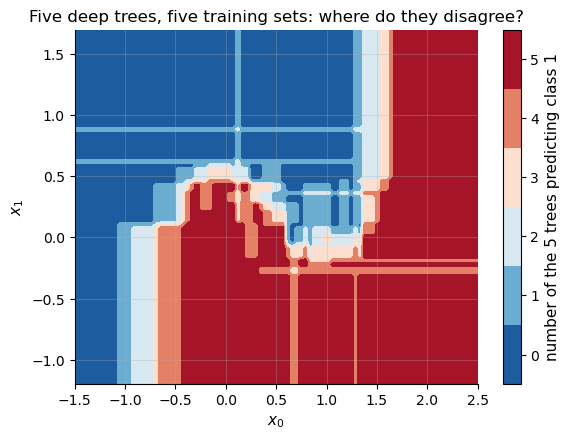

test accuracy of the five trees: [0.878 0.869 0.863 0.889 0.86 ]
share of the plane where the five trees do not all agree: 24%


In [4]:
# Five independent training sets from the same distribution -> five deep trees
X_te, y_te = make_moons(1000, noise=0.3)                         # a common test set
g0, g1 = np.meshgrid(np.linspace(-1.5, 2.5, 90), np.linspace(-1.2, 1.7, 90))
grid = np.c_[g0.ravel(), g1.ravel()]
votes = np.zeros(len(grid)); accs = []
for s in range(5):
    Xs, ys = make_moons(200, noise=0.3)
    tree = DecisionTreeClassifier(min_samp_split=2, max_depth=None)  # a single fully grown tree
    tree.fit(Xs, ys.reshape(-1, 1))
    votes += np.array(tree.predict(grid))
    accs.append(np.mean(np.array(tree.predict(X_te)) == y_te))

fig, ax = plt.subplots(figsize=(6.5, 4.6))
cf = ax.contourf(g0, g1, votes.reshape(g0.shape), levels=np.arange(-0.5, 6), cmap="RdBu_r")
fig.colorbar(cf, ticks=range(6), label="number of the 5 trees predicting class 1")
ax.set(title="Five deep trees, five training sets: where do they disagree?", xlabel="$x_0$", ylabel="$x_1$"); plt.show()
print("test accuracy of the five trees:", np.round(accs, 3))
print(f"share of the plane where the five trees do not all agree: {np.mean((votes > 0) & (votes < 5)):.0%}")

Deep red and deep blue areas are where all five trees agree. Every intermediate shade is a region where the prediction depends on *which* training sample was drawn, and there is a large band of such regions between the two moons. Each tree has roughly the same test accuracy, but they make **different** mistakes. That is the signature of variance. If we could average over many training sets, those idiosyncratic mistakes would cancel. We only have one training set, but the bootstrap lets us imitate many.

## 3. Why a random forest fits this problem

**Bagging.** Breiman's *bootstrap aggregating* (1996) builds $T$ trees, each on a bootstrap resample of the training data ($n$ draws **with replacement**), and lets them vote. Each resample is a plausible alternative training set, so the trees differ in the way trees from genuinely different training sets would, and the vote averages away part of their variance.

**Random feature subsets.** Breiman's *random forest* (2001) adds a second source of randomness: at each node, the split search may only look at $m_{\text{try}}$ randomly chosen features. Section 4.2 shows that the benefit of averaging is limited by how **correlated** the trees are. If one feature is very strong, every bagged tree splits on it first and the trees end up similar. Restricting the candidate features forces the trees to differ, which lowers the correlation.

**Strengths.** Forests keep the low bias of deep trees while cutting variance. They need little tuning, are robust to irrelevant features, and require no feature scaling (they inherit this from trees). The trees can be trained independently, in parallel.

**Weaknesses.** They lose the single tree's interpretability. Prediction costs $T$ times as much. And because averaging cannot remove *bias*, a forest of shallow, underfitting trees is still an underfitting model.

**Compared with the other methods in this repo.** Bagging attacks **variance**: it averages many low-bias, high-variance trees grown independently. Boosting ([AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb), [Gradient Boosting](../GradientBoostRegression/GradientBoostRegression_Walkthrough.ipynb), [XGBoost](../XGBoost/XGBoost_Walkthrough.ipynb)) attacks **bias**: it adds many high-bias, low-variance shallow trees grown *sequentially*, each one correcting the errors of the ensemble so far.

## 4. Core concepts, theory and math

### 4.1 Bootstrap samples

**Concept.** A bootstrap sample draws $n$ indices uniformly **with replacement** from $\{0, \dots, n-1\}$. Some samples appear several times and others not at all.

**Math.** A particular sample $i$ is missed by a single draw with probability $1 - \frac1n$. The $n$ draws are independent, so

$$
P(i \notin \text{bootstrap sample}) = \Big(1 - \frac{1}{n}\Big)^n \xrightarrow{\,n\to\infty\,} e^{-1} \approx 0.368 . \tag{1}
$$

To see the limit, take logarithms and use $\ln(1 - u) = -u - \tfrac{u^2}{2} - \dots$: $\;n \ln(1 - \tfrac1n) = n\big(-\tfrac1n - \tfrac{1}{2n^2} - \dots\big) = -1 - \tfrac{1}{2n} - \dots \to -1$.

So each bootstrap sample contains on average a fraction $1 - (1-\frac1n)^n \approx 63.2\%$ of the *distinct* original samples. The remaining $\approx 36.8\%$ are "out-of-bag" for that tree. More generally, the number of copies $N_i$ of sample $i$ is $\mathrm{Binomial}(n, \tfrac1n)$, which for large $n$ is approximately $\mathrm{Poisson}(1)$:

$$
P(N_i = k) \approx \frac{e^{-1}}{k!}, \qquad k = 0, 1, 2, \dots \tag{2}
$$

Eq. (2) will matter in Section 4.5.

**Illustration.** The exact finite-$n$ coverage approaching its limit.

In [5]:
# Illustration only — Eq. (1): expected fraction of distinct samples in a bootstrap sample
ns = np.array([2, 5, 10, 20, 50, 100, 1000])
coverage = 1 - (1 - 1 / ns) ** ns
for n_, c in zip(ns, coverage):
    print(f"n = {n_:>5}: expected distinct fraction = {c:.4f}")
print(f"limit 1 - 1/e = {1 - np.exp(-1):.4f}")

n =     2: expected distinct fraction = 0.7500
n =     5: expected distinct fraction = 0.6723
n =    10: expected distinct fraction = 0.6513
n =    20: expected distinct fraction = 0.6415
n =    50: expected distinct fraction = 0.6358
n =   100: expected distinct fraction = 0.6340
n =  1000: expected distinct fraction = 0.6323
limit 1 - 1/e = 0.6321


**Your implementation.** `RandomForestClassifier.bootstrap_sample(X, Y)` draws `self.rng.choice(n, n, replace=True)` from the forest's own generator and returns the resampled rows. Passing the row *indices* themselves as `X` reveals which rows were drawn.

In [6]:
n = 200
rf_tmp = RandomForestClassifier(random_state=1)          # the forest's own random generator, seeded with 1
idx_col = np.arange(n).reshape(-1, 1)
fractions, counts = [], []
for _ in range(2000):
    drawn, _ = rf_tmp.bootstrap_sample(idx_col, idx_col)  # rows of the index column = the drawn indices
    c = np.bincount(drawn.ravel(), minlength=n)
    fractions.append(np.mean(c > 0)); counts.append(c)
counts = np.concatenate(counts)
print(f"mean distinct fraction over 2,000 bootstrap samples (n = {n}): {np.mean(fractions):.4f}")
print("empirical P(N_i = k), k = 0..5:", np.round([np.mean(counts == k) for k in range(6)], 4))

mean distinct fraction over 2,000 bootstrap samples (n = 200): 0.6333
empirical P(N_i = k), k = 0..5: [0.3667 0.3692 0.1846 0.0609 0.0152 0.0029]


In [7]:
# Check — Eqs. (1) and (2)
from math import factorial
exact = 1 - (1 - 1 / n) ** n
assert abs(np.mean(fractions) - exact) < 0.002
poisson = np.array([np.exp(-1) / factorial(k) for k in range(6)])
assert np.allclose([np.mean(counts == k) for k in range(6)], poisson, atol=0.005)
print(f"✓ distinct fraction {np.mean(fractions):.4f} vs exact {exact:.4f};  copy counts match Poisson(1): {np.round(poisson, 4)}")

✓ distinct fraction 0.6333 vs exact 0.6330;  copy counts match Poisson(1): [0.3679 0.3679 0.1839 0.0613 0.0153 0.0031]


The repo's bootstrap behaves exactly as Eqs. (1)–(2) predict. About 63% of the rows appear in each resample, and the number of copies of each row follows a Poisson(1) law: 37% of rows are absent, 37% appear once, 18% twice, 6% three times, and so on.

### 4.2 Why averaging reduces variance, and why correlation limits it

**Concept.** Think of each tree's output at a fixed input $x$ (for example, its vote for class 1, coded as 0 or 1) as a random variable, random because of the bootstrap sample and the feature subsets. All trees are built by the same random procedure, so these variables are *identically distributed*, with variance $\sigma^2$. But they are **not independent**: every tree is grown from the same training set, so any two trees have some positive correlation $\rho$.

**Math.** Let $Z_1, \dots, Z_T$ have common variance $\sigma^2$ and pairwise correlation $\rho$, so $\mathrm{Cov}(Z_s, Z_t) = \rho\sigma^2$ for $s \ne t$. The variance of their average expands into $T$ variance terms and $T(T-1)$ covariance terms:

$$
\mathrm{Var}\Big(\frac{1}{T}\sum_{t=1}^T Z_t\Big) = \frac{1}{T^2}\Big(\sum_t \mathrm{Var}(Z_t) + \sum_{s\ne t}\mathrm{Cov}(Z_s, Z_t)\Big) = \frac{1}{T^2}\Big(T\sigma^2 + T(T-1)\rho\sigma^2\Big) = \rho\,\sigma^2 + \frac{1-\rho}{T}\,\sigma^2 . \tag{3}
$$

The second term vanishes as $T\to\infty$, but the first does not. **However many trees we add, the variance never falls below $\rho\sigma^2$.** That is the precise reason for random feature subsets: they lower $\rho$ (at the cost of making each tree somewhat weaker, i.e. raising $\sigma^2$ or bias a little). Adding trees never hurts the variance; it simply has diminishing returns once $T$ is large relative to $1/\rho$.

**Illustration and check.** We simulate correlated variables as $Z_t = \sqrt{\rho}\,S + \sqrt{1-\rho}\,E_t$, with a shared standard-normal component $S$ and independent $E_t$. This gives exactly variance 1 and correlation $\rho$. We compare the measured variance of the average with Eq. (3).

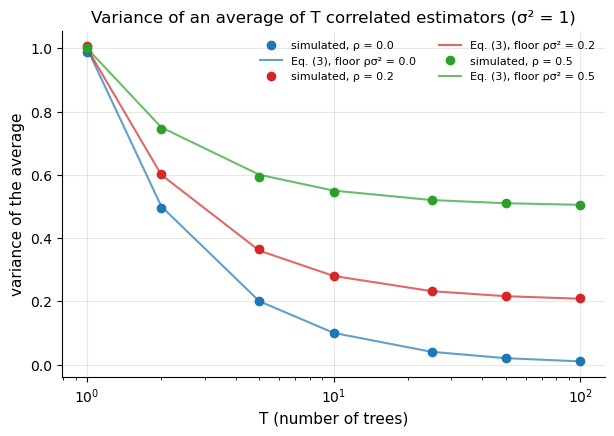

✓ simulated variances agree with Eq. (3) for every ρ and T


In [8]:
# Illustration only — Eq. (3) by simulation
Ts = np.array([1, 2, 5, 10, 25, 50, 100])
fig, ax = plt.subplots()
for rho, col in zip([0.0, 0.2, 0.5], CLASS_COLORS):
    S = rng.normal(size=(20_000, 1))
    E = rng.normal(size=(20_000, Ts.max()))
    Z = np.sqrt(rho) * S + np.sqrt(1 - rho) * E                 # 20,000 replications of T_max correlated "trees"
    measured = [Z[:, :T].mean(axis=1).var() for T in Ts]
    theory = rho + (1 - rho) / Ts
    ax.plot(Ts, measured, "o", color=col, label=f"simulated, ρ = {rho}")
    ax.plot(Ts, theory, "-", color=col, alpha=0.7, label=f"Eq. (3), floor ρσ² = {rho}")
    assert np.allclose(measured, theory, rtol=0.05, atol=0.003)
ax.set_xscale("log"); ax.set(title="Variance of an average of T correlated estimators (σ² = 1)", xlabel="T (number of trees)", ylabel="variance of the average")
ax.legend(ncol=2, fontsize=8); plt.show()
print("✓ simulated variances agree with Eq. (3) for every ρ and T")

With independent estimators ($\rho=0$), the variance falls like $1/T$. With $\rho = 0.5$, it never falls below $0.5$: after about 10 trees, further averaging buys almost nothing. Lowering the correlation between trees therefore matters as much as adding more of them. Section 7.3 measures $\rho$ for actual forests from this repo.

### 4.3 Majority voting

**Concept.** For classification, the forest combines its trees by a **plurality vote**: each tree casts one vote for its predicted class, and the most-voted class wins,

$$
\hat f(x) = \arg\max_{k}\; \sum_{t=1}^{T} \mathbb{1}[h_t(x) = k]. \tag{4}
$$

**Math: why voting helps.** Suppose, idealistically, that $T$ (odd) binary classifiers are *independent* and each is correct with probability $p > \tfrac12$. The vote is correct when more than half are correct:

$$
P(\text{vote correct}) = \sum_{k > T/2} \binom{T}{k} p^k (1-p)^{T-k} \xrightarrow{\,T\to\infty\,} 1 ,
$$

by the law of large numbers: the fraction of correct voters converges to $p > \tfrac12$. This is Condorcet's jury theorem. Real trees are correlated, so the improvement saturates, just as the variance does in Eq. (3).

**Illustration.**

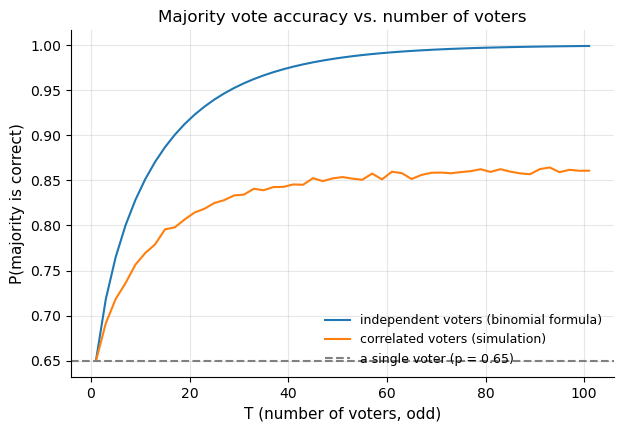

In [9]:
# Illustration only — accuracy of a majority vote of T voters, each correct with probability p = 0.65
from math import comb
p_c, T_odd = 0.65, np.arange(1, 102, 2)
indep = [sum(comb(T, k) * p_c**k * (1 - p_c)**(T - k) for k in range(T // 2 + 1, T + 1)) for T in T_odd]
# Correlated voters: each round, with probability 0.4 all voters copy one shared draw; otherwise they vote independently
corr = []
for T in T_odd:
    shared = rng.random(20_000) < 0.4
    common = rng.random(20_000) < p_c
    own = rng.random((20_000, T)) < p_c
    correct = np.where(shared[:, None], common[:, None], own)
    corr.append(np.mean(correct.sum(axis=1) > T / 2))
fig, ax = plt.subplots()
ax.plot(T_odd, indep, label="independent voters (binomial formula)")
ax.plot(T_odd, corr, label="correlated voters (simulation)")
ax.axhline(p_c, color="gray", ls="--", label=f"a single voter (p = {p_c})")
ax.set(title="Majority vote accuracy vs. number of voters", xlabel="T (number of voters, odd)", ylabel="P(majority is correct)")
ax.legend(); plt.show()

Independent voters drive the majority's accuracy toward 1. Correlated voters plateau, because whenever they share a mistake no number of extra votes can fix it. Here they are correct together 40% of the time with probability $0.65$, so the plateau is near $0.4 \times 0.65 + 0.6 \times 1 = 0.86$.

**Your implementation.** `majority_vote(predictions)` takes the $T$ votes for one sample, counts them with `np.unique(..., return_counts=True)`, and returns the most frequent label.

In [10]:
rf_demo = RandomForestClassifier()
for votes_ in [[1., 0., 1., 1., 0.], [2., 0., 2., 1., 1., 2.], [0., 1., 1., 0.], [1., 0., 0., 1.]]:
    print(f"votes {votes_} -> majority_vote = {rf_demo.majority_vote(np.array(votes_))}")

votes [1.0, 0.0, 1.0, 1.0, 0.0] -> majority_vote = 1.0
votes [2.0, 0.0, 2.0, 1.0, 1.0, 2.0] -> majority_vote = 2.0
votes [0.0, 1.0, 1.0, 0.0] -> majority_vote = 0.0
votes [1.0, 0.0, 0.0, 1.0] -> majority_vote = 0.0


In [11]:
# Check — agreement with Eq. (4) on 500 random vote vectors, ties included (ties -> smallest label)
for _ in range(500):
    v = rng.integers(0, 3, size=rng.integers(1, 12)).astype(float)
    assert rf_demo.majority_vote(v) == np.argmax(np.bincount(v.astype(int)))
print("✓ majority_vote returns the plurality class of Eq. (4); ties go to the smallest label")

✓ majority_vote returns the plurality class of Eq. (4); ties go to the smallest label


`majority_vote` implements the plurality vote of Eq. (4). The last two examples are 2–2 ties, and both return class 0 whatever the order of the votes.

> 🔧 **Fixed in the code — deterministic tie-breaking.**
> *Originally:* `majority_vote` returned `max(set(votes), key=votes.count)`. On a tie, the winner was whichever class Python's `set` happened to iterate over first, an implementation detail rather than a rule. The forest's tree had the analogous problem in its leaves (`max(y, key=y.count)` depends on sample order).
> *Now:* both use `np.unique(..., return_counts=True)` and take the first maximum, so ties always go to the smallest label (RandomForest.py, lines 96–99). Using an odd number of trees still avoids ties altogether in binary problems.

### 4.4 Random feature subsets at every node

**Concept.** In `DecisionTreeRandomForest.py`, every call to `get_best_split` first calls `get_random_features(num_feat)`. That method returns either all features or a random subset of size $m_{\text{try}}$, and only those features are searched. Because the subset is redrawn **at every node**, one tree can still use every feature. It just cannot always pick the globally best one.

**Math.** The code's rules for $m_{\text{try}}$ (after the fixes described below):

| `max_features` | $m_{\text{try}}$ |
|---|---|
| `None` | all $m$ features (plain bagging) |
| `'sqrt'` (the forest's default) | $\max(1, \lfloor\sqrt{m}\rfloor)$ |
| `'log2'` | $\max(1, \lfloor\log_2 m\rfloor)$ |
| an `int` $k$ | $\max(1, \min(k, m))$ |
| a `float` $f \in (0, 1]$ | $\max(1, \lfloor f\,m\rfloor)$, a fraction of the features, as in scikit-learn |
| anything else | `ValueError` |

The features are drawn **without replacement** with `self.rng.choice(num_feat, max_feat, replace=False)`, using the tree's own random generator. If none of the sampled features can split a node (they are all constant there), the search continues with the remaining features. scikit-learn does the same, so a tree never stops early just because of an unlucky draw.

**Your implementation and check.**

In [12]:
for mf in [None, "sqrt", "log2", 3, 0.5]:
    t = DecisionTreeClassifier(max_features=mf)
    sizes = {len(list(t.get_random_features(9))) for _ in range(50)}
    print(f"max_features={str(mf):<5} with m = 9: subset size(s) seen = {sizes}")
print("max_features='log2' with m = 1: subset size =", len(DecisionTreeClassifier(max_features="log2").get_random_features(1)))
try:
    DecisionTreeClassifier(max_features="auto").get_random_features(9)
except ValueError as err:
    print("max_features='auto' ->", type(err).__name__ + ":", err)

for _ in range(200):
    m_ = int(rng.integers(2, 40)); t = DecisionTreeClassifier(max_features="sqrt")
    sub = np.asarray(t.get_random_features(m_))
    assert len(sub) == int(np.sqrt(m_)) and len(set(sub)) == len(sub) and sub.max() < m_
print("✓ 'sqrt' gives floor(sqrt(m)) distinct, valid feature indices for every m tested")

max_features=None  with m = 9: subset size(s) seen = {9}
max_features=sqrt  with m = 9: subset size(s) seen = {3}
max_features=log2  with m = 9: subset size(s) seen = {3}
max_features=3     with m = 9: subset size(s) seen = {3}
max_features=0.5   with m = 9: subset size(s) seen = {4}
max_features='log2' with m = 1: subset size = 1
max_features='auto' -> ValueError: max_features must be None, 'sqrt', 'log2', a positive int, or a float in (0, 1]
✓ 'sqrt' gives floor(sqrt(m)) distinct, valid feature indices for every m tested


With $m = 9$, the subset sizes follow the table: `None` gives 9, `'sqrt'` gives 3, `'log2'` gives 3, `3` gives 3, and `0.5` gives $\lfloor 4.5\rfloor = 4$. On the 2-feature data sets used for plotting, `'sqrt'` means $\lfloor\sqrt 2\rfloor = 1$: each node chooses one of the two features at random and splits only on it.

> 🔧 **Fixed in the code — `max_features` edge cases.**
> *Originally:* a float such as `0.5` silently fell through to "all features" (scikit-learn reads it as a fraction). `'log2'` with a single feature gave $\lfloor\log_2 1\rfloor = 0$ features, so no split was ever searched. Any unknown value also silently meant "all features".
> *Now:* floats are fractions, at least one feature is always searched, and unknown values raise `ValueError` (DecisionTreeRandomForest.py, lines 108–127).

### 4.5 The forest's tree, and the bootstrap-duplicate crash that was fixed

`DecisionTreeRandomForest.DecisionTreeClassifier` is the classifier from `DecisionTree.py` with these changes:
- the `max_features` argument (§4.4);
- a `random_state` that seeds the tree's **own** generator `self.rng` (§5);
- a strict depth test `curr_depth < self.max_depth`, so `max_depth=d` really means depth $d$, and `None` means unlimited.

In [13]:
X_m, y_m = make_moons(200, noise=0.3)
print("max_depth | actual depth")
for md in [1, 2, 3, 5, None]:
    t = DecisionTreeClassifier(min_samp_split=2, max_depth=md); t.fit(X_m, y_m)
    print(f"{str(md):>9} | {tree_depth(t.root):>12}")
    if md is not None:
        assert tree_depth(t.root) == md

max_depth | actual depth
        1 |            1
        2 |            2
        3 |            3


        5 |            5
     None |           11


> 🔧 **Fixed in the code — bootstrap duplicates used to crash deep forests.**
> *Originally:* the tree inherited the classifier's weakness. If every sample in a node had the same feature vector, `get_best_split` found no valid threshold and returned `{}`, and `build_tree` raised `KeyError: 'info_gain'`, even for a pure node. With continuous features that requires **duplicate rows**, and bootstrap sampling creates duplicates by design (Eq. 2). It was the most serious bug in the repo: while this notebook was being written, *every* forest of depth-12 trees with `min_samp_split` of 2 or 3 crashed, and only `min_samp_split` ≥ 8 made crashes rare.
> *Now:* `build_tree` tests `best_split.get('info_gain', -inf) > 0` (DecisionTreeRandomForest.py, line 56), so a node of identical rows simply becomes a leaf.

**Why the crash was so frequent.** A node made only of copies of one row was split, and crashed, if it had at least `min_samp_split` samples and the depth limit had not been reached. In a deep tree, a row drawn $k$ times often ends up isolated in such a node, so the risk was governed by $P(N_i \ge \texttt{min\_samp\_split})$. With $T$ trees and $n$ rows, the expected number of rows drawn at least $k$ times somewhere in the forest is about $T\,n\,P(N \ge k)$, using the Poisson(1) law of Eq. (2). The cell below evaluates that number for a 20-tree forest on 200 rows. It then fits ten fully grown forests (`min_samp_split=2`, `max_depth=None`) with the fixed code and counts how many rows each bootstrap sample duplicated.

In [14]:
from math import exp
def p_at_least(k):                                   # Poisson(1) tail, Eq. (2)
    return 1 - sum(exp(-1) / factorial(i) for i in range(k))

print("k | P(N >= k) | expected # rows drawn >= k times in a 20-tree forest on 200 rows")
for k in [2, 3, 5, 8, 10]:
    print(f"{k:>2}| {p_at_least(k):.2e}  | {20 * 200 * p_at_least(k):10.4f}")

X_c, y_c = make_moons(200, noise=0.3)
dup_rows = []
for seed in range(1, 11):
    f = RandomForestClassifier(n_estimators=20, min_samp_split=2, max_depth=None, random_state=seed)
    f.fit(X_c, y_c)                                      # fully grown trees: crashed before the fix
    dup_rows.append(np.mean([np.sum(np.bincount(idx, minlength=200) >= 2) for idx in f.bootstrap_indices_]))
print(f"\n✓ 10/10 fully grown forests fitted; on average {np.mean(dup_rows):.0f} of 200 rows were duplicated in each bootstrap sample")

k | P(N >= k) | expected # rows drawn >= k times in a 20-tree forest on 200 rows
 2| 2.64e-01  |  1056.9645
 3| 8.03e-02  |   321.2056
 5| 3.66e-03  |    14.6394
 8| 1.02e-05  |     0.0410
10| 1.11e-07  |     0.0004



✓ 10/10 fully grown forests fitted; on average 53 of 200 rows were duplicated in each bootstrap sample


With `min_samp_split=2`, a forest contains about a thousand row-copies that can form a node of identical rows. Before the fix, every deep forest therefore crashed. Now all ten fully grown forests fit: each tree resamples roughly 53 rows two or more times ($n\,P(N\ge2) \approx 0.26 \times 200$), and every node made only of such copies simply becomes a leaf. From here on, the notebook uses **textbook fully grown trees** (`min_samp_split=2`, `max_depth=None`).

## 5. Implementation walkthrough, in the order the code runs

```
RandomForestClassifier(n_estimators, min_samp_split, max_depth, max_features, bootstrap, random_state)
  __init__  ── self.rng = np.random.default_rng(random_state)           (private generator)
  fit(X, Y) ── self.rng restarted from random_state
               for i in range(n_estimators):
                  indices = self.rng.choice(n, n, replace=True)  (if bootstrap)   Eq. (1)
                  self.bootstrap_indices_.append(indices)
                  tree = DecisionTreeClassifier(..., max_features, random_state = self.rng.integers(...))
                  tree.fit(X[indices], Y[indices])   (get_random_features at every node, §4.4)
  predict(X) ── P = [tree.predict(X) for each tree]  → array (T, n) → transpose (n, T)
                  for each sample: majority_vote(its T votes)                      Eq. (4)
  get_feature_importance(feature_names=None) ── Σ over trees of calculate_tree_importance(root) / T
```

**`__init__` (RandomForest.py, lines 17–35).** Stores the hyperparameters, rejects `n_estimators < 1`, and creates the forest's private generator `self.rng = np.random.default_rng(random_state)`.

**`bootstrap_sample(X, Y)` (lines 37–41).** `self.rng.choice(num_samples, num_samples, replace=True)`, Eq. (1). `fit` performs the same draw inline, so that it can record the indices.

**`fit(X, Y)` (lines 43–75).** Accepts `Y` as a 1-D vector or a column. It restarts `self.rng` from `random_state`, so refitting the same object reproduces the same forest. Then, for each $i$, it draws the bootstrap indices (or uses all rows if `bootstrap=False`), stores them in `self.bootstrap_indices_`, builds a tree whose `random_state` is a fresh integer drawn from the forest's generator, fits it, and appends it.

**`predict(X)` (lines 77–94).** Raises a clear `ValueError` if the forest has no trees. Otherwise it collects every tree's predictions into an array of shape $(T, n)$, transposes it to $(n, T)$, and applies `majority_vote` row by row, returning a Python list of labels. There is no `predict_proba`: the vote shares that would estimate class probabilities are computed implicitly but not exposed.

**`majority_vote(predictions)` (lines 96–99).** Eq. (4), with deterministic ties (§4.3).

**`get_feature_importance(feature_names=None)` and `calculate_tree_importance(node, num_features)` (lines 101–138).** Covered in §7.4.

**`DecisionTreeRandomForest.get_random_features(num_feat)` (lines 108–127).** §4.4. Everything else in that file (`get_best_split`, `split`, `information_gain`, `gini_index`, `entropy`, `calculate_leaf_value`, `print_tree`, `fit`, `predict`, `make_prediction`) follows the code walked through in the [Decision Tree notebook](../DecisionTree/DecisionTree_Walkthrough.ipynb#5.-Implementation-walkthrough,-in-the-order-the-code-runs), including that notebook's fixes (input validation, string labels, `is not None`). The split criterion here is Gini.

> 🔧 **Fixed in the code — randomness no longer lives in NumPy's global state.**
> *Originally:* the forest called `np.random.seed(random_state)` in its `__init__`, and **every tree** called `np.random.seed(random_state + i)` in its own `__init__`. That had three consequences. (1) Calling `fit` a second time on the same object gave a *different* forest: in a check made while writing this notebook, 0.8% of test predictions changed. (2) Fitting a forest silently reset the global generator for any other code using `np.random`. (3) Because of `... if self.random_state else None`, `random_state=0` was treated as "no seed" for the trees.
> *Now:* the forest and each tree own a `np.random.default_rng` generator. The forest's generator is restarted in `fit` and hands each tree its own seed. The global state is never touched. The cell below checks all three points.

In [15]:
X_r, y_r = make_moons(200, noise=0.3); X_rt, y_rt = make_moons(500, noise=0.3)
for seed in [3, 0]:
    forest = RandomForestClassifier(n_estimators=5, max_depth=None, random_state=seed)
    forest.fit(X_r, y_r); first = np.array(forest.predict(X_rt))
    forest.fit(X_r, y_r); second = np.array(forest.predict(X_rt))             # same object, refit
    fresh = RandomForestClassifier(n_estimators=5, max_depth=None, random_state=seed)
    fresh.fit(X_r, y_r); third = np.array(fresh.predict(X_rt))                # new object, same seed
    assert np.array_equal(first, second) and np.array_equal(first, third)
    print(f"random_state={seed}: refit and a fresh object both reproduce the forest exactly")
np.random.seed(123); before = np.random.random()
np.random.seed(123); RandomForestClassifier(n_estimators=3, random_state=1).fit(X_r, y_r); after = np.random.random()
assert before == after
print("✓ fitting a forest leaves NumPy's global random state untouched")

random_state=3: refit and a fresh object both reproduce the forest exactly


random_state=0: refit and a fresh object both reproduce the forest exactly
✓ fitting a forest leaves NumPy's global random state untouched


## 6. Worked numerical example: a 3-tree forest on 10 samples

We follow every random choice of a small forest: `n_estimators=3`, `max_depth=2`, `min_samp_split=2`, `max_features='sqrt'` (1 of the 2 features at each node), `random_state=5`. The forest records the rows each tree was trained on in `bootstrap_indices_`, so we can display every bootstrap sample.

In [16]:
X_toy = np.array([[1, 2], [2, 5], [3, 1], [4, 7], [5, 3], [6, 8], [7, 4], [8, 6], [3, 8], [9, 2]], dtype=float)
y_toy = np.array([0, 0, 0, 1, 0, 1, 1, 1, 1, 0], dtype=float)
print(" i  x0  x1  y")
for i, ((a, b_), c) in enumerate(zip(X_toy, y_toy)):
    print(f"{i:>2} {a:>3.0f} {b_:>3.0f} {c:>2.0f}")

 i  x0  x1  y
 0   1   2  0
 1   2   5  0
 2   3   1  0
 3   4   7  1
 4   5   3  0
 5   6   8  1
 6   7   4  1
 7   8   6  1
 8   3   8  1
 9   9   2  0


In [17]:
toy_forest = RandomForestClassifier(n_estimators=3, min_samp_split=2, max_depth=2, max_features="sqrt", random_state=5)
toy_forest.fit(X_toy, y_toy)
for i, (tree, idx) in enumerate(zip(toy_forest.trees, toy_forest.bootstrap_indices_)):
    oob = sorted(set(range(len(X_toy))) - set(idx.tolist()))
    print(f"--- tree {i}: bootstrap indices {sorted(idx.tolist())}")
    print(f"    distinct rows used: {len(set(idx.tolist()))}/10, out-of-bag rows: {oob}")
    tree.print_tree()

--- tree 0: bootstrap indices [0, 0, 2, 4, 5, 6, 6, 8, 8, 9]
    distinct rows used: 7/10, out-of-bag rows: [1, 3, 7]
X_1 <= 3.0 ? 0.5
    left:0.0
    right:1.0
--- tree 1: bootstrap indices [0, 0, 0, 1, 1, 1, 3, 4, 5, 9]
    distinct rows used: 6/10, out-of-bag rows: [2, 6, 7, 8]
X_1 <= 5.0 ? 0.31999999999999984
    left:0.0
    right:1.0
--- tree 2: bootstrap indices [1, 2, 2, 2, 4, 7, 7, 8, 8, 9]
    distinct rows used: 6/10, out-of-bag rows: [0, 3, 5, 6]
X_0 <= 5.0 ? 0.06095238095238098
    left:X_1 <= 5.0 ? 0.40816326530612246
        left:0.0
        right:1.0
    right:X_0 <= 8.0 ? 0.4444444444444444
        left:1.0
        right:0.0


In [18]:
# Check — each tree is exactly the tree you get by fitting the repo's tree to its recorded bootstrap sample
for tree, idx in zip(toy_forest.trees, toy_forest.bootstrap_indices_):
    replica = DecisionTreeClassifier(min_samp_split=2, max_depth=2, max_features="sqrt", random_state=tree.random_state)
    replica.fit(X_toy[idx], y_toy[idx])
    assert np.array_equal(np.array(replica.predict(X_toy)), np.array(tree.predict(X_toy)))
print("✓ refitting each tree on its recorded bootstrap sample (with its recorded seed) reproduces it exactly")

✓ refitting each tree on its recorded bootstrap sample (with its recorded seed) reproduces it exactly


Each tree saw a different resample. Row 0 appears three times in tree 1's sample, and three or four of the ten rows are out-of-bag for each tree. For $n = 10$, Eq. (1) predicts $10 \times (1 - 0.651) \approx 3.5$ on average. The three roots all differ ($x_1 \le 3$, $x_1 \le 5$, $x_0 \le 5$), partly because the data differ and partly because each node could examine only one randomly chosen feature. Trees 0 and 1 stop after a single split because both children are already pure. Tree 2's root split has a small gain ($0.061$), but it sets up two very effective splits below it. The final check confirms that each stored tree is exactly what the repo's tree produces from its recorded bootstrap sample and seed.

Now the vote, for three query points:

In [19]:
Q = np.array([[2.0, 2.0], [5.0, 6.0], [8.0, 3.0]])
P = np.array([t.predict(Q) for t in toy_forest.trees])          # shape (T, n_queries)
print("query       tree0 tree1 tree2 | majority_vote | forest.predict")
for q, final in zip(range(len(Q)), toy_forest.predict(Q)):
    print(f"{str(Q[q]):<11} {P[0, q]:>5.0f} {P[1, q]:>5.0f} {P[2, q]:>5.0f} | {toy_forest.majority_vote(P[:, q]):>13.0f} | {final:>14.0f}")
print("\ntraining accuracy of the forest:", np.mean(np.array(toy_forest.predict(X_toy)) == y_toy))

query       tree0 tree1 tree2 | majority_vote | forest.predict
[2. 2.]         0     0     0 |             0 |              0
[5. 6.]         1     1     1 |             1 |              1
[8. 3.]         0     0     1 |             0 |              0

training accuracy of the forest: 1.0


The first two query points are unanimous. For $(8, 3)$, two trees vote class 0 and one votes class 1, so the forest predicts 0: the dissenting tree's quirk is outvoted. This is the variance-cancelling mechanism of §4.2–4.3 in miniature.

## 7. Visual experiments

All forests from here on use **fully grown trees** (`min_samp_split=2`, `max_depth=None`), the textbook random-forest setting, plus `random_state` seeds for reproducibility.

### 7.1 One tree versus a forest

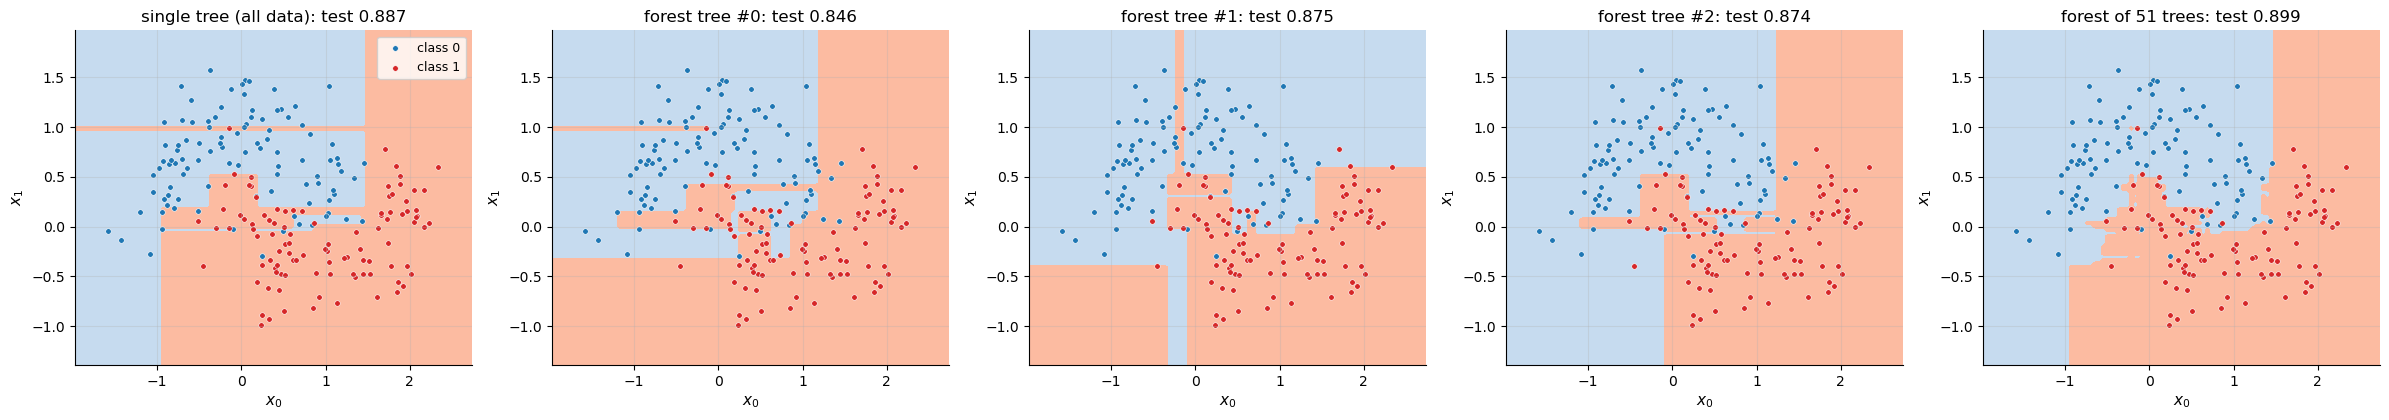

mean test accuracy of the 51 individual forest trees: 0.852


In [20]:
X_tr, y_tr = make_moons(200, noise=0.3)
X_test, y_test = make_moons(1000, noise=0.3)
common = dict(min_samp_split=2, max_depth=None)          # fully grown trees

single = DecisionTreeClassifier(**common); single.fit(X_tr, y_tr.reshape(-1, 1))
forest50 = RandomForestClassifier(n_estimators=51, max_features="sqrt", random_state=7, **common)
forest50.fit(X_tr, y_tr.reshape(-1, 1))
acc = lambda model: np.mean(np.array(model.predict(X_test)) == y_test)

fig, axes = plt.subplots(1, 5, figsize=(24, 4.3))
plot_decision_regions(single.predict, X_tr, y_tr, ax=axes[0], grid_n=100, title=f"single tree (all data): test {acc(single):.3f}")
for k in range(3):
    t = forest50.trees[k]
    plot_decision_regions(t.predict, X_tr, y_tr, ax=axes[k + 1], grid_n=100, legend=False, title=f"forest tree #{k}: test {acc(t):.3f}")
plot_decision_regions(forest50.predict, X_tr, y_tr, ax=axes[4], grid_n=100, legend=False, title=f"forest of 51 trees: test {acc(forest50):.3f}")
plt.tight_layout(); plt.show()
print(f"mean test accuracy of the 51 individual forest trees: {np.mean([acc(t) for t in forest50.trees]):.3f}")

What to notice:
- Each **individual forest tree** (middle panels) is a rough, blocky classifier. Because it sees only a bootstrap sample and only one random feature per split, it is on average *worse* than a single tree grown on all the data (compare the printed mean with the first panel). The members also differ visibly from one another.
- Their **vote** (right) follows the curve of the moons more closely. The odd stripes that individual trees draw are outvoted. The forest's test accuracy is above the average member's and above the single tree's.
- This is the trade made in §4.2: each member is weakened (higher $\sigma^2$) in exchange for a much lower correlation $\rho$, and the vote wins on balance.

### 7.2 Test accuracy as trees are added

We record each tree's test predictions once, then use the repo's `majority_vote` on the first $t$ trees for $t = 1, 3, 5, \dots$. Odd $t$ avoids ties. The same is done for plain bagging (`max_features=None`).

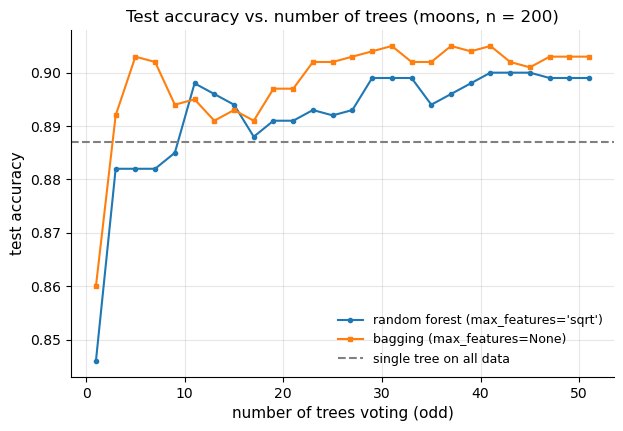

forest: 1 tree 0.846 -> 51 trees 0.899;  bagging: 1 tree 0.860 -> 51 trees 0.903


In [21]:
def staged_vote_accuracy(model, X, y):
    P = np.array([tree.predict(X) for tree in model.trees])            # (T, n)
    ts = np.arange(1, len(model.trees) + 1, 2)
    accs = [np.mean(np.array([model.majority_vote(P[:t, i]) for i in range(P.shape[1])]) == y) for t in ts]
    return ts, np.array(accs)

bagging = RandomForestClassifier(n_estimators=51, max_features=None, random_state=7, **common)
bagging.fit(X_tr, y_tr.reshape(-1, 1))
ts, acc_rf = staged_vote_accuracy(forest50, X_test, y_test)
_, acc_bag = staged_vote_accuracy(bagging, X_test, y_test)

fig, ax = plt.subplots()
ax.plot(ts, acc_rf, "o-", ms=3, label="random forest (max_features='sqrt')")
ax.plot(ts, acc_bag, "s-", ms=3, label="bagging (max_features=None)")
ax.axhline(acc(single), color="gray", ls="--", label="single tree on all data")
ax.set(title="Test accuracy vs. number of trees (moons, n = 200)", xlabel="number of trees voting (odd)", ylabel="test accuracy")
ax.legend(); plt.show()
print(f"forest: 1 tree {acc_rf[0]:.3f} -> 51 trees {acc_rf[-1]:.3f};  bagging: 1 tree {acc_bag[0]:.3f} -> 51 trees {acc_bag[-1]:.3f}")

Both curves rise steeply over the first few trees, keep creeping up until roughly 20–30 trees, and then level off. This is the saturation predicted by Eq. (3) and by the correlated-voter curve of §4.3. Beyond that point the curves wander within about ±0.005. That is smaller than the standard error of an accuracy measured on 1,000 test points ($\sqrt{0.9 \times 0.1/1000} \approx 0.009$), so it is noise from individual trees joining the vote, not a real decline. Adding trees does not make the *expected* accuracy worse. On this 2-feature problem, the feature-subsampled forest and plain bagging end up close to each other. With only two features, "pick 1 of 2 at random" is a blunt instrument. The next experiment uses more features, where `max_features` matters more.

### 7.3 Decorrelation: the effect of `max_features`

Whether restricting the candidate features helps depends on what the *other* features are. We build two 6-feature versions of the moons data (noise level 0.2):
- **Noise features.** The two moons coordinates plus four pure-noise columns.
- **Redundant features.** Three independently noisy copies of each moons coordinate ($x_j + 0.25\,\varepsilon$). Every column is informative, but no single column is clean.

For each version and each `max_features`, we fit a 21-tree forest and measure three things: the average accuracy of individual trees, the average pairwise **correlation** $\rho$ between the trees' test predictions, and the forest's accuracy. The differences between settings are only a percentage point or two, similar to the noise of one test set, so everything is **averaged over 3 independent replications** (new training set, test set and forest seed each time).

noise features (means over 3 replications):
  max_features (m_try) | mean single-tree acc | mean pairwise ρ | forest acc
             1 (1)     |                0.760 |           0.393 |      0.893
          sqrt (2)     |                0.819 |           0.557 |      0.909
          None (6)     |                0.884 |           0.780 |      0.919
redundant features (means over 3 replications):
  max_features (m_try) | mean single-tree acc | mean pairwise ρ | forest acc
             1 (1)     |                0.840 |           0.617 |      0.911
          sqrt (2)     |                0.854 |           0.675 |      0.909
          None (6)     |                0.855 |           0.731 |      0.892


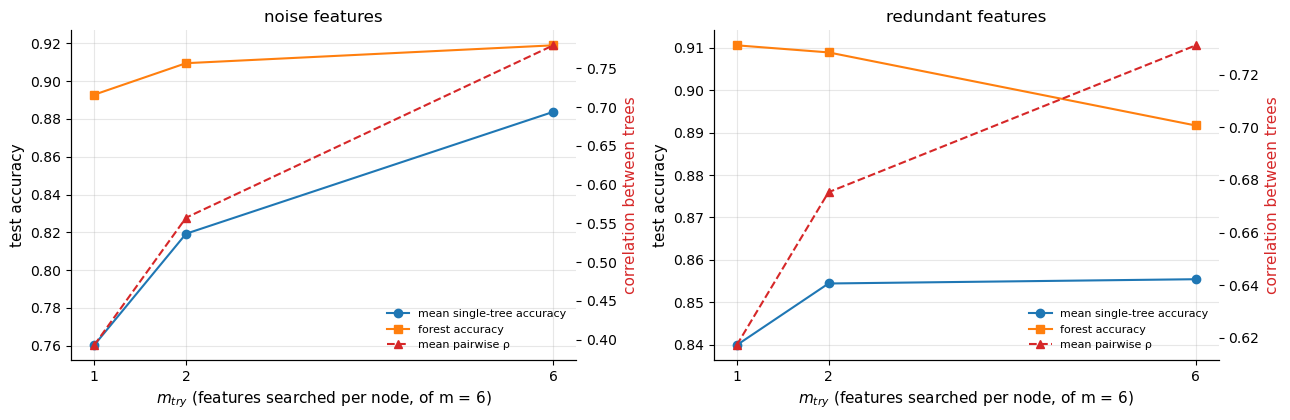

In [22]:
def add_noise_features(X, k=4):
    return np.c_[X, rng.normal(size=(len(X), k))]
def redundant_copies(X):
    return np.column_stack([X[:, j] + 0.25 * rng.normal(size=len(X)) for j in (0, 1, 0, 1, 0, 1)])

mf_list, mtry, n_reps = [1, "sqrt", None], [1, 2, 6], 3
table = {name: np.zeros((len(mf_list), 3)) for name in ("noise features", "redundant features")}
for rep in range(n_reps):
    Xb_tr, yb_tr = make_moons(200, noise=0.2); Xb_te, yb_te = make_moons(600, noise=0.2)
    for name, make in (("noise features", add_noise_features), ("redundant features", redundant_copies)):
        A_tr, A_te = make(Xb_tr), make(Xb_te)
        for a, mf in enumerate(mf_list):
            f = RandomForestClassifier(n_estimators=21, max_features=mf, random_state=rep + 1, **common)
            f.fit(A_tr, yb_tr.reshape(-1, 1))
            P = np.array([t.predict(A_te) for t in f.trees])           # (21, n_test)
            C = np.corrcoef(P)
            table[name][a] += np.array([np.mean(P == yb_te, axis=1).mean(), C[np.triu_indices_from(C, k=1)].mean(),
                                        np.mean(np.array(f.predict(A_te)) == yb_te)]) / n_reps
X6_tr = add_noise_features(X_tr)                                     # used for feature importance in §7.4

for name, vals in table.items():
    print(f"{name} (means over {n_reps} replications):\n  max_features (m_try) | mean single-tree acc | mean pairwise ρ | forest acc")
    for mf, k, (a1, rho_, af) in zip(mf_list, mtry, vals):
        print(f"  {str(mf):>12} ({k})     | {a1:>20.3f} | {rho_:>15.3f} | {af:>10.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, (name, vals) in zip(axes, table.items()):
    ax.plot(mtry, vals[:, 0], "o-", label="mean single-tree accuracy")
    ax.plot(mtry, vals[:, 2], "s-", label="forest accuracy")
    ax.set(title=name, xlabel="$m_{try}$ (features searched per node, of m = 6)", ylabel="test accuracy", xticks=mtry)
    ax2 = ax.twinx(); ax2.plot(mtry, vals[:, 1], "^--", color=CLASS_COLORS[1], label="mean pairwise ρ")
    ax2.set_ylabel("correlation between trees", color=CLASS_COLORS[1]); ax2.grid(False)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax.legend(h1 + h2, l1 + l2, loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

Both tables show the two sides of the trade-off in Eq. (3). As $m_{\text{try}}$ shrinks, **correlation $\rho$ falls**: a node can no longer always pick the best available feature, so the trees diverge. But **individual trees get weaker**, for the same reason. Which effect wins depends on the data:
- **Noise features.** Forest accuracy *rises* with $m_{\text{try}}$, and searching all features is best. With $m_{\text{try}} = 1$, two-thirds of the time a node sees only a noise column and must make a useless split. The trees become so weak that the large drop in $\rho$ cannot compensate.
- **Redundant features.** Here the forests that subsample features beat the one that searches all six. With every copy available, each node picks whichever noisy copy happens to look best, so all trees make similar choices (highest $\rho$). Forcing different nodes and trees onto different copies decorrelates them at almost no cost in individual strength, because every copy is informative.

So feature subsampling helps most when many features carry overlapping signal, and too aggressive a setting hurts when most features are irrelevant. $\lfloor\sqrt m\rfloor$ is a reasonable compromise across both cases here, but `max_features` is worth tuning. The differences are a percentage point or two, which is why they were averaged over replications.

### 7.4 Feature importance

**Concept.** A forest can report how much each feature contributed to its splits. The repo's `get_feature_importance(feature_names)` walks every tree with `calculate_tree_importance`, adds each decision node's stored `info_gain` to the importance of the feature it split on, and divides the totals by `n_estimators`:

$$
\mathrm{Imp}(j) = \frac{1}{T}\sum_{t=1}^T \sum_{\text{nodes } v \text{ of tree } t:\ j_v = j} \Delta_v .
$$

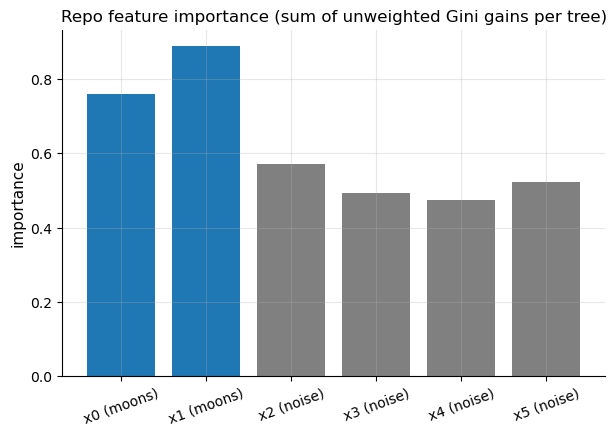

importances: [0.76  0.888 0.571 0.492 0.474 0.523]  sum = 3.709
✓ get_feature_importance equals the per-node sum of info_gain / n_estimators


In [23]:
f_imp = RandomForestClassifier(n_estimators=31, max_features="sqrt", random_state=11, **common)
f_imp.fit(X6_tr, y_tr.reshape(-1, 1))
names = ["x0 (moons)", "x1 (moons)", "x2 (noise)", "x3 (noise)", "x4 (noise)", "x5 (noise)"]
imp = f_imp.get_feature_importance(names)
assert np.allclose(imp, f_imp.get_feature_importance())       # feature_names is optional

# Check — recompute the definition above directly from the trees' nodes
manual_imp = np.zeros(6)
for t in f_imp.trees:
    for node in iter_nodes(t.root):
        if node.value is None and node.info_gain:
            manual_imp[node.feature_index] += node.info_gain
assert np.allclose(imp, manual_imp / len(f_imp.trees))

fig, ax = plt.subplots()
ax.bar(names, imp, color=[CLASS_COLORS[0]] * 2 + ["gray"] * 4)
ax.set(title="Repo feature importance (sum of unweighted Gini gains per tree)", ylabel="importance"); plt.xticks(rotation=20); plt.show()
print("importances:", np.round(imp, 3), " sum =", round(imp.sum(), 3))
print("✓ get_feature_importance equals the per-node sum of info_gain / n_estimators")

The two moons features stand out. The noise features still get substantial credit, because deep trees with $m_{\text{try}} = 2$ are often *forced* to split on noise, and every such split has some positive gain on the training data.

> ⚠️ **Note on the implementation — importance is unweighted and unnormalised.**
> In the usual "mean decrease in impurity" (MDI, as in scikit-learn), each node's impurity decrease is weighted by the **fraction of training samples reaching that node**, $\frac{|S_v|}{n}\Delta_v$, and the importances are normalised to sum to 1. The repo adds the raw `info_gain` of every node. Because `information_gain` is a *per-node* quantity (already normalised by the node's size), a deep node with 10 samples counts as much as the root with 200 when the two have equal $\Delta$. That inflates the importance of features used deep in the trees, which is typically where noise features are used. The totals do not sum to 1 (see the printed sum), so they can only be compared within one model. (`get_feature_importance` originally returned `None` unless `feature_names` was given, because it used the names only to count the features. It now takes the count from the training data when the names are omitted.) Even weighted MDI is known to favour noise and high-cardinality features. Permutation importance on held-out data is the more trustworthy alternative.

### 7.5 Variance reduction, measured

Section 2 showed five deep trees disagreeing. We now measure the variance that Eq. (3) describes directly. For 10 independent training sets, we fit a single tree and a 25-tree forest. At each point $x$ of a fixed grid we record the single tree's output $h(x) \in \{0, 1\}$ and the forest's **vote share** $v(x) = \frac1T\sum_t h_t(x)$, the average that the majority vote thresholds at $\tfrac12$. The variance of each across the 10 training sets is the classification counterpart of the variance term in the [bias–variance decomposition](../DecisionTreeRegression/DecisionTreeRegression_Walkthrough.ipynb#7.3-Bias–variance-decomposition,-measured).

average variance across training sets: single-tree output 0.0489   forest vote share 0.0119   (ratio 0.24)
mean test accuracy over the 10 training sets: single tree 0.863, forest 0.885


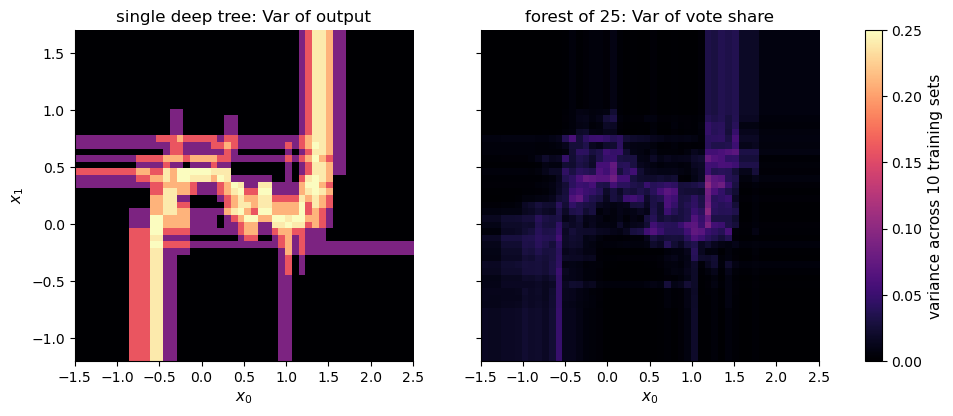

In [24]:
grid_small = np.c_[np.repeat(np.linspace(-1.5, 2.5, 50), 50), np.tile(np.linspace(-1.2, 1.7, 50), 50)]
H_tree, V_forest, acc_tree, acc_forest = [], [], [], []
for s in range(10):
    Xs, ys = make_moons(200, noise=0.3)
    t = DecisionTreeClassifier(**common); t.fit(Xs, ys.reshape(-1, 1))
    f = RandomForestClassifier(n_estimators=25, max_features="sqrt", random_state=100 + s, **common); f.fit(Xs, ys.reshape(-1, 1))
    H_tree.append(np.array(t.predict(grid_small)))
    V_forest.append(np.mean([tr.predict(grid_small) for tr in f.trees], axis=0))      # vote share per grid point
    acc_tree.append(np.mean(np.array(t.predict(X_test)) == y_test)); acc_forest.append(np.mean(np.array(f.predict(X_test)) == y_test))
var_tree, var_forest = np.var(H_tree, axis=0), np.var(V_forest, axis=0)
print(f"average variance across training sets: single-tree output {var_tree.mean():.4f}   forest vote share {var_forest.mean():.4f}"
      f"   (ratio {var_forest.mean() / var_tree.mean():.2f})")
print(f"mean test accuracy over the 10 training sets: single tree {np.mean(acc_tree):.3f}, forest {np.mean(acc_forest):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), sharey=True)
for ax, V_, ttl in zip(axes, [var_tree, var_forest], ["single deep tree: Var of output", "forest of 25: Var of vote share"]):
    im = ax.imshow(V_.reshape(50, 50).T, origin="lower", extent=[-1.5, 2.5, -1.2, 1.7], aspect="auto", cmap="magma", vmin=0, vmax=0.25)
    ax.set(title=ttl, xlabel="$x_0$"); ax.grid(False)
axes[0].set_ylabel("$x_1$"); fig.colorbar(im, ax=axes, label="variance across 10 training sets"); plt.show()

The single tree's variance appears as long horizontal and vertical stripes: whole axis-aligned slabs of the plane flip their label depending on where one threshold happened to land. The forest's vote share varies much less, and what variance remains is concentrated along the curved class boundary, where the label is genuinely ambiguous. The printed ratio is the empirical counterpart of Eq. (3). It does not approach $1/25$, because the trees in a forest are positively correlated, and the floor $\rho\sigma^2$ remains. The forest's *labels* are just the vote share thresholded at $\tfrac12$, so close to the boundary they can still flip from one training set to the next. The reduced variance is what lifts the forest's average test accuracy above the single tree's.

## 8. Hyperparameters

| Hyperparameter | What it controls | Effect |
|---|---|---|
| `n_estimators` ($T$) | number of trees | More trees means lower variance, with diminishing returns (Eq. 3) and linear cost. It does not cause overfitting. |
| `max_depth` | depth of each tree (`None` = fully grown) | Deep trees give low bias and high variance, which is what averaging fixes; shallow trees make an underfitting forest. |
| `min_samp_split` | smallest node that may be split | Regularises each tree; the textbook forest uses 2 (fully grown trees). |
| `max_features` | $m_{\text{try}}$ per node | Small values decorrelate trees but weaken them; this helps with redundant features and hurts with many irrelevant ones (§7.3). |
| `bootstrap` | resample rows or not | `False` removes row randomness. With `max_features=None` as well, every tree is identical (demonstrated below). |
| `random_state` | seeds the forest's private generator | Same seed, same forest, even on refit (§5). |

The cell below confirms the last point of the table and shows the effect of tree depth inside a forest.

bootstrap=False and max_features=None -> all trees identical: True


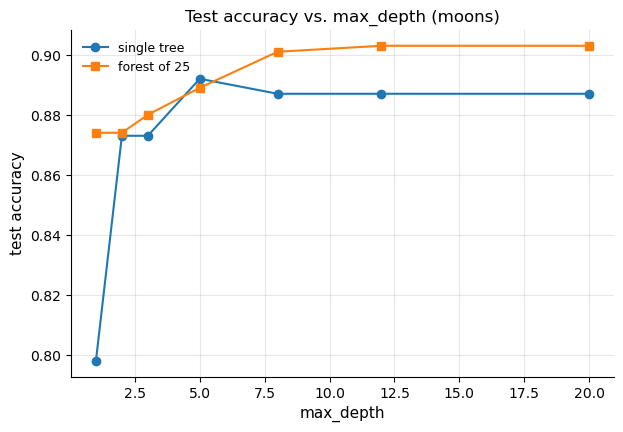

max_depth= 1: single tree 0.798   forest 0.874
max_depth= 2: single tree 0.873   forest 0.874
max_depth= 3: single tree 0.873   forest 0.880
max_depth= 5: single tree 0.892   forest 0.889
max_depth= 8: single tree 0.887   forest 0.901
max_depth=12: single tree 0.887   forest 0.903
max_depth=20: single tree 0.887   forest 0.903


In [25]:
same = RandomForestClassifier(n_estimators=4, min_samp_split=2, max_depth=8, max_features=None, bootstrap=False, random_state=1)
same.fit(X_tr, y_tr.reshape(-1, 1))
P_same = np.array([t.predict(X_test) for t in same.trees])
print("bootstrap=False and max_features=None -> all trees identical:", all(np.array_equal(P_same[0], p) for p in P_same))

depth_rows = []
for md in [1, 2, 3, 5, 8, 12, 20]:
    f = RandomForestClassifier(n_estimators=25, min_samp_split=2, max_depth=md, max_features="sqrt", random_state=5)
    f.fit(X_tr, y_tr.reshape(-1, 1))
    t = DecisionTreeClassifier(min_samp_split=2, max_depth=md); t.fit(X_tr, y_tr.reshape(-1, 1))
    depth_rows.append((md, acc(t), acc(f)))
fig, ax = plt.subplots()
ax.plot([r_[0] for r_ in depth_rows], [r_[1] for r_ in depth_rows], "o-", label="single tree")
ax.plot([r_[0] for r_ in depth_rows], [r_[2] for r_ in depth_rows], "s-", label="forest of 25")
ax.set(title="Test accuracy vs. max_depth (moons)", xlabel="max_depth", ylabel="test accuracy"); ax.legend(); plt.show()
for r_ in depth_rows:
    print(f"max_depth={r_[0]:>2}: single tree {r_[1]:.3f}   forest {r_[2]:.3f}")

With `bootstrap=False` and all features, the trees are deterministic copies of one tree, so the "forest" is just that tree; both sources of randomness are needed for bagging to do anything. The depth comparison has three regimes.
- **Depth 1.** The forest of stumps clearly beats the single stump. Its 25 stumps cut along *different* features at different thresholds, and their vote forms a staircase boundary that no single stump can draw. This is an additive combination of simple rules, the idea that boosting develops systematically.
- **Depths 2–5.** The two are close, and the ordering can go either way.
- **Deeper trees.** The forest is consistently ahead. This is the high-variance regime that averaging is designed for, and why random forests are normally built from fully grown trees.

What voting cannot remove is bias: a forest's accuracy is limited by how expressive its individual trees are.

## 9. Complexity and limitations

**Training.** $T$ trees, each built on $n$ (bootstrap) rows but searching only $m_{\text{try}}$ features per node. With this repo's $O(m\,|S|^2)$-per-node search (see the [Decision Tree notebook](../DecisionTree/DecisionTree_Walkthrough.ipynb#9.-Complexity-and-limitations)), a forest costs about $O(T\cdot D\cdot m_{\text{try}}\cdot n^2)$. Feature subsampling therefore also speeds training up, by a factor $m/m_{\text{try}}$. The trees are independent, so production libraries train them in parallel (`n_jobs` in scikit-learn); this implementation trains them one after another.

**Prediction.** $O(T\cdot D)$ per point, $T$ times a single tree's cost. **Memory.** $T$ trees.

| Limitation of this implementation | Consequence | What e.g. scikit-learn does |
|---|---|---|
| Votes only, no `predict_proba` | no probability estimates or soft voting | averages per-tree class probabilities (soft voting) |
| No out-of-bag (OOB) score | needs a separate validation set | `oob_score=True` evaluates each row on the trees that did not see it (§4.1) |
| Unweighted, unnormalised importance | biased toward deep / noise splits (§7.4) | sample-weighted MDI normalised to 1; permutation importance |
| Sequential tree building; $O(n^2)$ per node | slow | parallel trees, sorted-sweep split search |
| Gini only; thresholds at observed values | as in the base tree | criterion option; midpoints |

Bugs found during this walkthrough and **fixed in the code**:

| Original behaviour | Fix |
|---|---|
| Empty `best_split` → `KeyError` on duplicate bootstrap rows: deep forests crashed unless `min_samp_split` ≳ 8 | node becomes a leaf (§4.5) |
| Global `np.random` seeding in forest *and* trees: refit ≠ first fit, side effects on other code, `random_state=0` unseeded for the trees | private `default_rng` generators (§5) |
| `max_features` float meant "all features"; `'log2'` with $m=1$ gave 0 features; unknown values accepted | fraction semantics, at least 1 feature, `ValueError` (§4.4) |
| No fallback when all sampled features are constant in a node | remaining features searched (§4.4) |
| Vote and leaf ties broken by `set` / sample order | ties go to the smallest label (§4.3) |
| `get_feature_importance()` returned `None` without `feature_names`; 1-D `Y` rejected | optional names; 1-D labels accepted (§5, §7.4) |

## 10. Summary

- Deep trees have low bias but high **variance**: retrained on new data, they make different mistakes (§2).
- **Bagging** trains each tree on a bootstrap resample. Each resample contains about $63.2\%$ of the distinct rows, and copy counts follow Poisson(1) (Eqs. 1–2, checked against `bootstrap_sample`). The forest predicts by **plurality vote** (Eq. 4, `majority_vote`).
- Averaging $T$ trees with pairwise correlation $\rho$ leaves variance $\rho\sigma^2 + \frac{1-\rho}{T}\sigma^2$ (Eq. 3, verified by simulation). Adding trees has diminishing returns, and lowering $\rho$ is what **random feature subsets** (`get_random_features`, redrawn at every node) are for, at the price of weaker individual trees. That trade paid off with redundant features, and too small an $m_{\text{try}}$ backfired with noise features (§7.3).
- Empirically, a forest of deep trees beats a typical member and the single tree. Across training sets, its vote share varied only about a quarter as much as a single tree's output (§7.1–7.5). The advantage is largest and most reliable for deep trees, because voting removes variance, not bias (§8).
- Fixed in the code during this walkthrough: the `KeyError` crash on bootstrap duplicates (its frequency is predicted by the Poisson tail; fully grown forests now work); global NumPy seeding (now private generators, so refits are reproducible); `max_features` edge cases; tie-breaking; optional `feature_names`. Remaining design caveats: feature importance is unweighted and unnormalised, and there is no `predict_proba` or OOB score (though `bootstrap_indices_` now makes OOB estimates possible).

**Next:** reducing *bias* instead of variance, by training trees sequentially: [AdaBoost](../AdaBoost/AdaBoost_Walkthrough.ipynb).